# Notebook goals


- standardize obs names, gene metadata, genome
- concatenate all samples of a dataset into one h5ad
- filter cells based on QC thresholds
- log metrics and filter decisions in QC log with cellular resolution
- save QC plots and new h5ad

alternatively, you can use this notebook to load and inspect previously determined QC filtering thresholds 

# User input

In [1]:
DATASET = 'SC1-01'# which dataset to process

LOAD_FILTERING_THRESHOLDS = False # option to inspect previously determined QC filtering thresholds

## notable datasets

### SC1-07

For this dataset there was no raw data available. 

Hence, for this dataset we skipped the alignment and cellbender steps, and instead downloaded the available h5ads into the 2a_cellbender/wo_empty_droplets folder, renamed a few obs columns and manually changed the file names to match the file name pattern SC1-07_<sample_name>.h5ad

As the dataset had a different genome, the genome is translated to GRCm39 in this notebook as well (c.f. IS_WRONG_GENOME flag further down below, which is automatically set when running DATASET = "SC1-07")

### Smartseq data, such as SC2-04

For this technology, it is necessary to normalize the data using the canonical transcript length.

The steps required for this will be performed automatically for datasets whose "Technology" is "smart-seq" in the dataset metadata.

Furthermore, Smartseq data does not require empty droplet removal. Hence, this dataset is only being converted to h5ad during in the 1_Cellbender.sh script.

# imports

In [2]:
# No need to restart notebook when editing custom packages
%load_ext autoreload
%autoreload 2

In [3]:
# Built-in imports
from pathlib import Path
from glob import glob
from tqdm import tqdm
import matplotlib.pyplot as plt
import json
import warnings
import tempfile
import os 

# Dependency imports
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad 
from dotenv import dotenv_values

# Custom imports
from hm3d_utils.qc import (
    sanitize_anndata,
    normalize_smartseq,
    prepare_adata_for_visualization,
    clean_and_export_adata,
)

from hm3d_utils.plotting import (
    plot_qc_umaps,
    plot_qc_filtered_vs_clean,
    plot_qc_filtered_vs_manual_vs_clean,
    plot_qc_thr_hists
    )

warnings.filterwarnings("ignore")

In [4]:
# Project-wide Constants
CONFIG = dotenv_values("config.env") # assuming kernel located at the root of the directory
DATA_ROOT_DIR = Path(CONFIG['DATADIR'])
RCPARAMS = CONFIG['MPLSTYLE']

In [5]:
# Notebook-specific constants; automatically derived depending on user input above

DATADIR = DATA_ROOT_DIR / "2a_cellbender" / "outs" / "wo_empty_droplets"
OUTDIR = DATA_ROOT_DIR / '2b_clean'
HVG_FP = DATA_ROOT_DIR / "1c_aligned" / "highly_variable_genes.csv" # some preliminary HVGs used to get UMAPs for QC
PLOTDIR = OUTDIR / "qc_plots" / DATASET
GENE_METADATA_PATH = DATA_ROOT_DIR / "gene_metadata.csv"
DATASET_METADATA_PATH = Path("resources/dataset_metadata.csv")  # assuming kernel to be located at root of the repo
CELL_HISTORY = DATA_ROOT_DIR / "qc_log.csv"
if LOAD_FILTERING_THRESHOLDS == True:
    FILTERING_SUMMARY_PATH = f'{OUTDIR}/filtering_summary_new.json' 

if DATASET == "SC1-07":
    IS_WRONG_GENOME = True
else:
    IS_WRONG_GENOME = False


metadata_df = pd.read_csv(DATASET_METADATA_PATH)
if "smart" in metadata_df.loc[metadata_df.ReferenceID == DATASET, "Technology"].iloc[0].lower():
    IS_SMARTSEQ = True
else:
    IS_SMARTSEQ = False
del metadata_df

# Load data and sanitize


i.e. standardize gene metadata, obs_names, and genome


Samples are grouped by dataset under the assumption they follow similar technical artefacts as such similar thresholds are acceptable.

In [6]:
fps = glob(Path(DATADIR, f"{DATASET}*.h5ad").as_posix())
fps

['/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754362.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754359.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754356.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754358.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754354.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754360.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754361.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754357.h5ad',
 '/REDACTED-path/HypoMap3D-data/v0.9/2a_cellbender/outs/wo_empty_droplets/SC1-01_SAMN18754353.h5ad']

In [7]:
adata_dict = {}

genemeta = pd.read_csv(GENE_METADATA_PATH)

for fp in tqdm(sorted(fps), desc='Reading AnnDatas'):
    
    # Derive inputs for function
    dataset_sample_str = fp.split("/")[-1].split(f".h5ad")[0] # get dataset and sample info
    dataset_str = dataset_sample_str.split("_")[0]

    sample_str = "-".join(dataset_sample_str.split("_")[1:]) # samples can contain "_". harmonize with "-". e.g. SC2-13_M2TX_200924_203_C01 -> M2TX-200924-203-C01
    if sample_str == "": # fallback for dataset SC1-04 consisting of 1 sample whose name is "SC1-04" without an additional sample string
        sample_str = dataset_str
    
    adata = sc.read_h5ad(fp)

    adata = sanitize_anndata(adata, 
        genemeta, 
        dataset_name = dataset_str,
        sample_name = sample_str,
        map_new_genome=IS_WRONG_GENOME)
    
    adata_dict[Path(fp).stem] = adata


Reading AnnDatas: 100%|█████████████████████████| 9/9 [01:29<00:00,  9.99s/it]


In [8]:
# no duplicated var names allowed!
assert not any(v.var_names.duplicated().any() for v in adata_dict.values())

### get anndata for visualization


concats all samples into one dataset, calculates quality control metrics and gets a umap representation calculated using the HVGs present in HVG_PF

In [9]:
adata = prepare_adata_for_visualization(adata_dict = adata_dict, hvg_fp = HVG_FP)

In [10]:
adata

AnnData object with n_obs × n_vars = 302738 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'distances', 'connectivities'

In [11]:
adata.obs.head()

,CellID,Dataset,Sample,total_counts,n_genes,pct_mito
SC1-01_SAMN18754353_AAACCCAAGCGTTCAT,SC1-01_SAMN18754353_AAACCCAAGCGTTCAT,SC1-01,SAMN18754353,1253,871,3.192338
SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01,SAMN18754353,17459,5884,0.131737
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01,SAMN18754353,17067,5727,0.117185
SC1-01_SAMN18754353_AAACCCAGTGAGATTA,SC1-01_SAMN18754353_AAACCCAGTGAGATTA,SC1-01,SAMN18754353,5183,2578,0.501640
SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,SC1-01,SAMN18754353,11905,4965,0.201596


### Let's visualise the behaviour of the QC metrics

... storing 'Dataset' as categorical
... storing 'Sample' as categorical


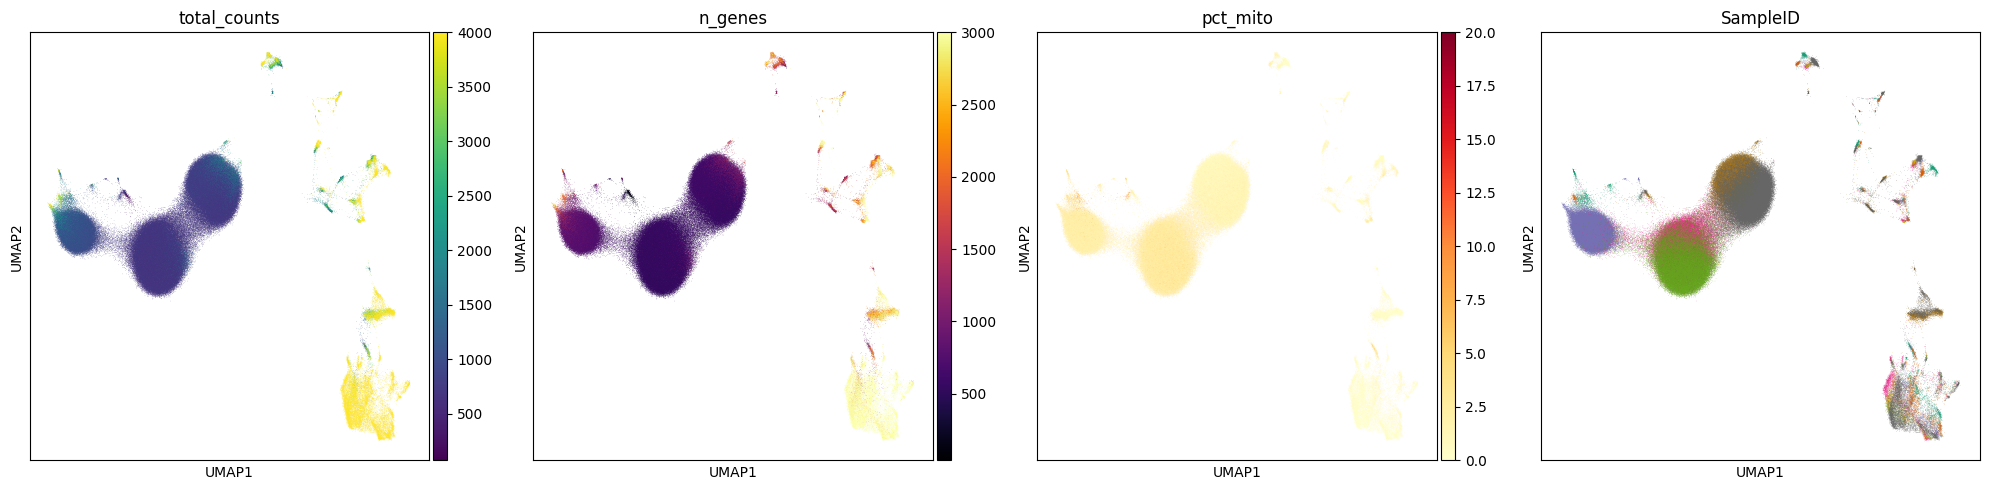

UMAP QC metrics saved to: /REDACTED-path/HypoMap3D-data/v0.9/2b_clean/qc_plots/SC1-01/umap_qc_metrics.png


In [12]:
plot_qc_umaps(adata, PLOTDIR)

### Let's set the thresholds


when run in LOAD_FILTERING_THRESHOLDS = True mode, previously set thresholds will be loaded here

In [13]:
if LOAD_FILTERING_THRESHOLDS == False:
    # set me
    MIN_GENES_THRESHOLD = 300
    MIN_COUNTS_THRESHOLD = 1500
    MAX_PCT_MITO_THRESHOLD = 5
    manually_removed_obs = []
    
else: 
    with open(FILTERING_SUMMARY_PATH, 'r') as io:
        filtsum = json.load(io)

    fsdf = pd.DataFrame.from_dict(filtsum).T

    MIN_GENES_THRESHOLD = fsdf.loc[DATASET, "min_genes_threshold"]
    MIN_COUNTS_THRESHOLD = fsdf.loc[DATASET, "min_counts_threshold"]
    MAX_PCT_MITO_THRESHOLD = fsdf.loc[DATASET, "max_pct_mito_threshold"]
    manually_removed_obs = fsdf.loc[DATASET, "manually_removed_obs"]

filter_mask = ((adata.obs['total_counts'] < MIN_COUNTS_THRESHOLD) |
               (adata.obs['n_genes'] < MIN_GENES_THRESHOLD) |
               (adata.obs['pct_mito'] > MAX_PCT_MITO_THRESHOLD)
               )

adata.obs['failed_qc'] = filter_mask

manual_mask = adata.obs.index.isin(manually_removed_obs)

adata.obs['manually_removed'] = manual_mask # will be added to failed_qc before the export

Figure saved to /REDACTED-path/HypoMap3D-data/v0.9/2b_clean/qc_plots/SC1-01/qc_thr.png


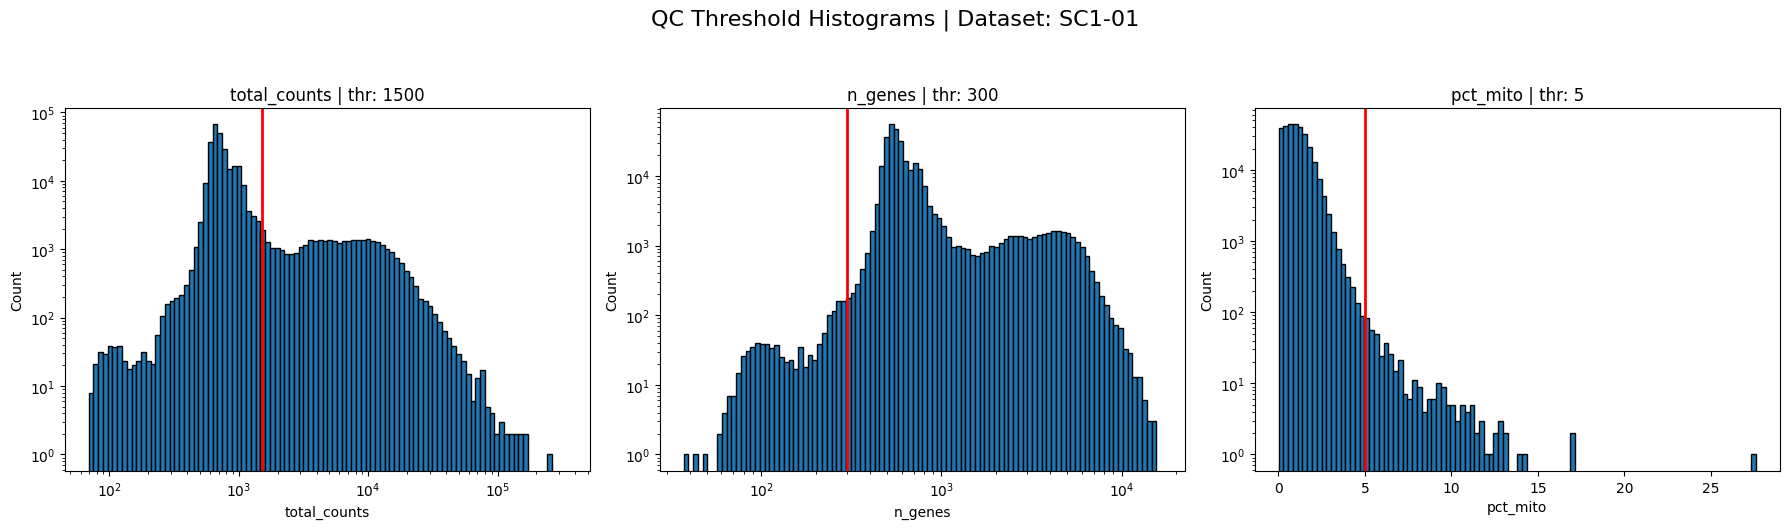

In [14]:
plot_qc_thr_hists(adata.obs,
    min_counts_threshold=MIN_COUNTS_THRESHOLD, 
    min_genes_threshold=MIN_GENES_THRESHOLD, 
    max_pct_mito_threshold=MAX_PCT_MITO_THRESHOLD,
    bins = 100,
    save_dir = PLOTDIR,
    dataset_id = DATASET
    )

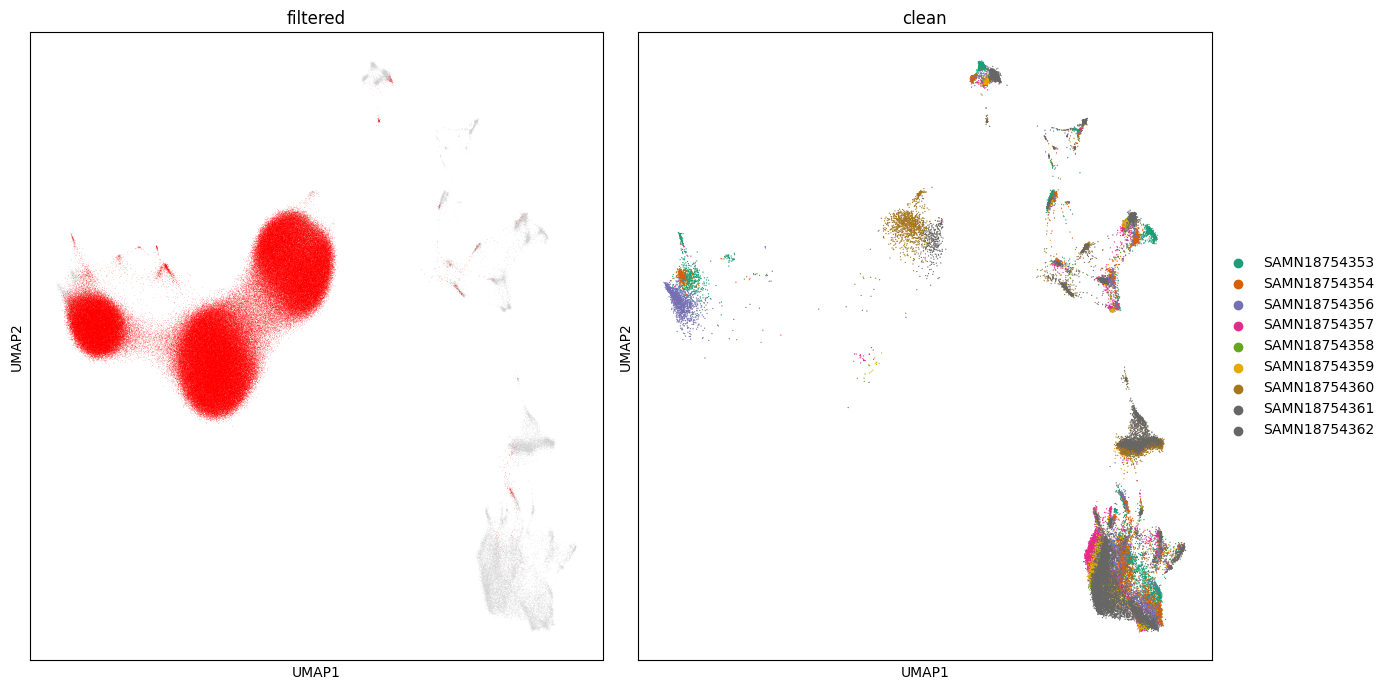

Filtered vs Clean UMAP saved to: /REDACTED-path/HypoMap3D-data/v0.9/2b_clean/qc_plots/SC1-01/umap_filtered_vs_clean.png


In [15]:
plot_qc_filtered_vs_clean(adata, PLOTDIR)


### Optional: Manually remove obs

1. Some clusters are clearly low quality as evidenced by low definition on UMAP i.e. blobs
2. Difficult to simply draw a circle and remove points, so perhaps try by cluster

the next few cells are kept in the notebook as an example but should be played with depending on the dataset

you could also investigate the expression of certain genes, e.g., "Rbfox3" == NeuN, to evaluate whether cells might be neurons or not

set DO_MANUAL_REMOVAL = True if you want to do some manual removal steps yourself

In [16]:
#sc.pl.umap(adata, color = "Rbfox3")

In [17]:
DO_MANUAL_REMOVAL = False

In [18]:
if DO_MANUAL_REMOVAL:
    # get different resolution leiden clusterings
    resolutions = [0.2, 0.5, ]
    for resolution in resolutions:
        sc.tl.leiden(adata, resolution = resolution, key_added = f"leiden_{resolution}", flavor = "igraph")

    sc.pl.umap(adata,
        color = [f"leiden_{r}" for r in resolutions], ncols=1)

In [19]:
if DO_MANUAL_REMOVAL:
    
    clusters_to_remove = [0,6,7]
    clusters_to_remove = [str(c) for c in clusters_to_remove]
    clustering_res = 0.2

    adata.obs["manually_removed"] = adata.obs[f"leiden_{clustering_res}"].isin(clusters_to_remove)

else:

    clusters_to_remove = None
    clustering_res = None 
    adata.obs["manually_removed"] = False

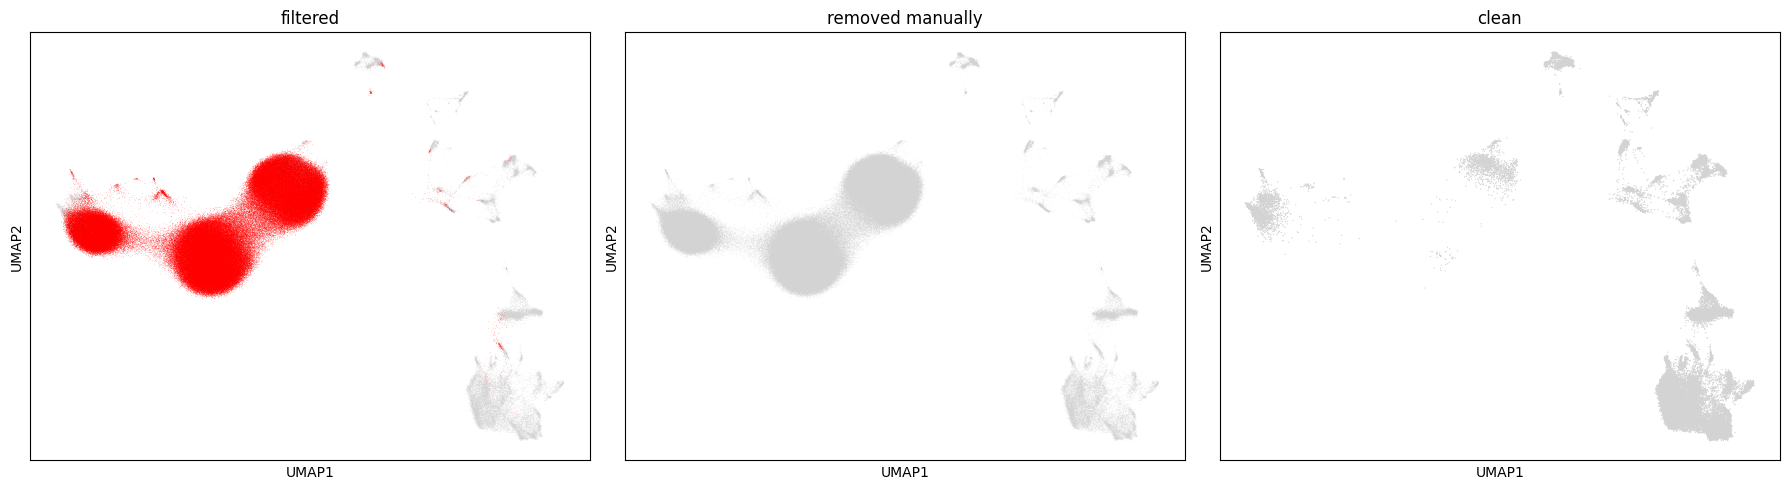

UMAP filtered vs manual vs clean saved to: /REDACTED-path/HypoMap3D-data/v0.9/2b_clean/qc_plots/SC1-01/umap_filtered_vs_manual_vs_clean.png


In [20]:
plot_qc_filtered_vs_manual_vs_clean(adata, PLOTDIR, clusters_to_remove = clusters_to_remove,
    removal_clustering_res = clustering_res)

In [21]:
if DO_MANUAL_REMOVAL:
    manually_removed_obs = adata[adata.obs.manually_removed].obs_names.values
else:
    manually_removed_obs = []

### Let's track the cells

In [22]:
track_cols = [c for c in adata.obs.columns if "leiden" not in c]
track_df = adata.obs.loc[:, track_cols].reset_index(drop=True)
track_df = track_df.rename(columns={"failed_qc": "failed_qc_thresholds", "manually_removed": "qc_manually_removed"})
track_df.head(3)

,CellID,Dataset,Sample,total_counts,n_genes,pct_mito,failed_qc_thresholds,qc_manually_removed
0,SC1-01_SAMN18754353_AAACCCAAGCGTTCAT,SC1-01,SAMN18754353,1253,871,3.192338,True,False
1,SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01,SAMN18754353,17459,5884,0.131737,False,False
2,SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01,SAMN18754353,17067,5727,0.117185,False,False


In [23]:
if not CELL_HISTORY.exists():
    # write new file with header
    track_df.to_csv(CELL_HISTORY, index=False)
else:
    # Load existing file
    existing_df = pd.read_csv(CELL_HISTORY)
    print(f"Current number of cells in QC log: {len(existing_df)}")

    # Ensure both dataframes have the same columns
    all_cols = sorted(set(existing_df.columns).union(set(track_df.columns)))

    existing_df = existing_df.reindex(columns=all_cols)
    track_df = track_df.reindex(columns=all_cols)

    print(f'{existing_df["CellID"].isin(track_df["CellID"]).sum()} cells already present. Will be removed')
    # Remove rows that have CellIDs present in the new dataframe
    existing_df = existing_df[~existing_df["CellID"].isin(track_df["CellID"])]
    n_pre_add = len(existing_df)

    print(f"Trying to add {len(track_df)} cells to QC log")
    # Concatenate with explicit outer join
    updated_df = pd.concat([existing_df, track_df], ignore_index=True, join="outer")

    print(f"Length of updated QC log: {len(updated_df)}")
    print(f"{len(updated_df) - n_pre_add} cells were successfully added")
    assert n_pre_add + len(track_df) == len(updated_df), "Not all cells were added to QC log"

    # Atomically replace cell history to avoid data corruption
    output_path = CELL_HISTORY
    output_dir = output_path.parent
    # Create temp file in same directory
    with tempfile.NamedTemporaryFile(mode="w", delete=False, dir=output_dir, suffix=".csv") as tmp:
        temp_path = Path(tmp.name)
        updated_df.to_csv(tmp.name, index=False)
    
    os.replace(temp_path, output_path)

Current number of cells in QC log: 3819292
26664 cells already present. Will be removed
Trying to add 302738 cells to QC log
Length of updated QC log: 4095366
302738 cells were successfully added


### Let's export the results

filtering out failed cells, trimming unnecessary attributes, cleaning

In [32]:
export_adata = clean_and_export_adata(
    adata = adata,
    min_counts_threshold = MIN_COUNTS_THRESHOLD,
    min_genes_threshold = MIN_GENES_THRESHOLD,
    max_pct_mito_threshold = MAX_PCT_MITO_THRESHOLD,
    manually_removed_obs = manually_removed_obs
)


In [33]:
# Normalize smart seq datasets by canonical transcript length
if IS_SMARTSEQ:

    path_to_transcript_lengths = "resources/Mus_musculus.GRCm39.110.woGm28040.canonical_transcript_lengths.csv" # tracked in repo
    
    export_adata = normalize_smartseq(export_adata, path_to_transcript_lengths)


In [ ]:

# Save to disk!
export_adata.write_h5ad(Path(OUTDIR, f"{DATASET}.h5ad"))

export_adata